In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [2]:
# Load training data
X_train = pd.read_csv("../results/X_train.csv")
y_train = pd.read_csv("../results/y_train.csv").squeeze("columns")

# Load validation data
X_val = pd.read_csv("../results/X_val.csv")
y_val = pd.read_csv("../results/y_val.csv").squeeze("columns")

# Load testing data
X_test = pd.read_csv("../results/X_test.csv")
y_test = pd.read_csv("../results/y_test.csv").squeeze("columns")

print("Datasets loaded successfully!")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Datasets loaded successfully!
Training: (7000, 10)
Validation: (1500, 10)
Testing: (1500, 10)


# Logistic Regression

In [3]:
lr_model = Pipeline([
    ('scaler', StandardScaler()),

    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train model
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [4]:
# Predict validation data

y_val_pred = lr_model.predict(X_val)

y_val_prob = lr_model.predict_proba(X_val)[:, 1]

# Calculate evaluation metrics

print("LOGISTIC REGRESSION - VALIDATION RESULTS")
print("----------------------------------------")

print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1-Score:", f1_score(y_val, y_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob))
print("PR-AUC:", average_precision_score(y_val, y_val_prob))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

LOGISTIC REGRESSION - VALIDATION RESULTS
----------------------------------------
Accuracy: 0.8626666666666667
Precision: 0.1702127659574468
Recall: 0.7843137254901961
F1-Score: 0.27972027972027974
ROC-AUC: 0.9048160326932705
PR-AUC: 0.35618139682746197

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.87      0.92      1449
           1       0.17      0.78      0.28        51

    accuracy                           0.86      1500
   macro avg       0.58      0.82      0.60      1500
weighted avg       0.96      0.86      0.90      1500



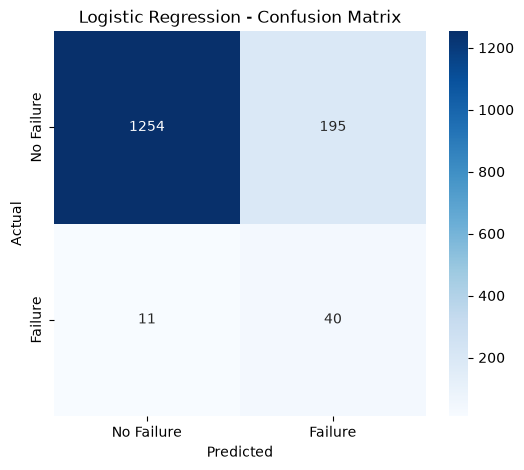

In [5]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### Metric	Target	Current result	Status
Recall	≥80%	78.43%	Below target
Precision	≥70%	17.02%	Below target
F1-score	≥0.75	0.28	Below target
ROC-AUC	≥0.95	Not calculated here	Pending

In [7]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Get failure probabilities
y_val_prob = lr_model.predict_proba(X_val)[:, 1]

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60]

results = []

for threshold in thresholds:

    y_pred = (
        y_val_prob >= threshold
    ).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1-Score': f1_score(y_val, y_pred)
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(3)

,Threshold,Precision,Recall,F1-Score
0,0.2,0.088,0.941,0.161
1,0.3,0.107,0.882,0.191
2,0.4,0.135,0.843,0.232
3,0.5,0.170,0.784,0.280
4,0.6,0.206,0.667,0.315


# Random Forest

In [8]:
from sklearn.ensemble import RandomForestClassifier

In [9]:
# Create Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest training completed")

Random Forest training completed


In [10]:
# Predict validation data

rf_val_pred = rf_model.predict(X_val)

rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

# Evaluation metrics

print("RANDOM FOREST - VALIDATION RESULTS")
print("----------------------------------")

print("Accuracy:", accuracy_score(y_val, rf_val_pred))
print("Precision:", precision_score(y_val, rf_val_pred))
print("Recall:", recall_score(y_val, rf_val_pred))
print("F1-Score:", f1_score(y_val, rf_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, rf_val_prob))
print("PR-AUC:", average_precision_score(y_val, rf_val_prob))

print("\nClassification Report:")
print(classification_report(y_val, rf_val_pred))

RANDOM FOREST - VALIDATION RESULTS
----------------------------------
Accuracy: 0.99
Precision: 0.8913043478260869
Recall: 0.803921568627451
F1-Score: 0.845360824742268
ROC-AUC: 0.9815559073871094
PR-AUC: 0.8731898018106969

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1449
           1       0.89      0.80      0.85        51

    accuracy                           0.99      1500
   macro avg       0.94      0.90      0.92      1500
weighted avg       0.99      0.99      0.99      1500



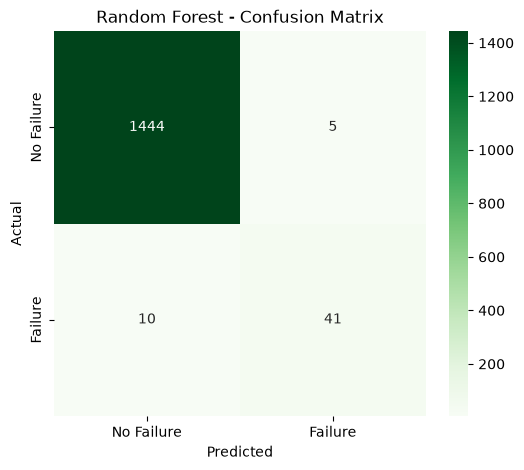

In [11]:
cm_rf = confusion_matrix(y_val, rf_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [12]:
# Random Forest probability predictions

rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

print("ROC-AUC:",
      roc_auc_score(y_val, rf_val_prob))

print("PR-AUC:",
      average_precision_score(y_val, rf_val_prob))

ROC-AUC: 0.9815559073871094
PR-AUC: 0.8731898018106969


# Gradient Boosting

In [13]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

In [14]:
# Calculate balanced sample weights
gb_sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

# Create Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train model with balanced sample weights
gb_model.fit(
    X_train,
    y_train,
    sample_weight=gb_sample_weights
)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [15]:
# Predict validation dataset

gb_val_pred = gb_model.predict(X_val)

gb_val_prob = gb_model.predict_proba(X_val)[:, 1]

# Calculate evaluation metrics

print("GRADIENT BOOSTING - VALIDATION RESULTS")
print("--------------------------------------")

print("Accuracy:", accuracy_score(y_val, gb_val_pred))
print("Precision:", precision_score(y_val, gb_val_pred))
print("Recall:", recall_score(y_val, gb_val_pred))
print("F1-Score:", f1_score(y_val, gb_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, gb_val_prob))
print("PR-AUC:", average_precision_score(y_val, gb_val_prob))

print("\nClassification Report:")
print(classification_report(y_val, gb_val_pred))

GRADIENT BOOSTING - VALIDATION RESULTS
--------------------------------------
Accuracy: 0.96
Precision: 0.45714285714285713
Recall: 0.9411764705882353
F1-Score: 0.6153846153846154
ROC-AUC: 0.9818739089838834
PR-AUC: 0.8943636019604463

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      1449
           1       0.46      0.94      0.62        51

    accuracy                           0.96      1500
   macro avg       0.73      0.95      0.80      1500
weighted avg       0.98      0.96      0.97      1500



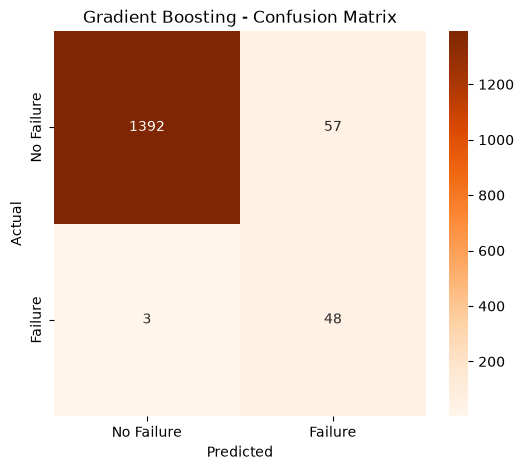

In [16]:
cm_gb = confusion_matrix(y_val, gb_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.title('Gradient Boosting - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [17]:
print("ROC-AUC:",
      roc_auc_score(y_val, gb_val_prob))

print("PR-AUC:",
      average_precision_score(y_val, gb_val_prob))

ROC-AUC: 0.9818739089838834
PR-AUC: 0.8943636019604463


# SMOTE

investigate whether SMOTE can improve the models.

In [18]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.preprocessing import StandardScaler

In [19]:
smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

In [21]:
rf_smote_model = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(
        sampling_strategy='auto',
        random_state=42,
        k_neighbors=5
    )),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

rf_smote_model.fit(X_train, y_train)

print("Random Forest with SMOTE training completed")

Random Forest with SMOTE training completed


In [22]:
rf_smote_pred = rf_smote_model.predict(X_val)

rf_smote_prob = rf_smote_model.predict_proba(X_val)[:, 1]

print("RANDOM FOREST WITH SMOTE")
print("------------------------")

print("Accuracy:", accuracy_score(y_val, rf_smote_pred))
print("Precision:", precision_score(y_val, rf_smote_pred))
print("Recall:", recall_score(y_val, rf_smote_pred))
print("F1-Score:", f1_score(y_val, rf_smote_pred))
print("ROC-AUC:", roc_auc_score(y_val, rf_smote_prob))
print("PR-AUC:", average_precision_score(y_val, rf_smote_prob))

RANDOM FOREST WITH SMOTE
------------------------
Accuracy: 0.9753333333333334
Precision: 0.5972222222222222
Recall: 0.8431372549019608
F1-Score: 0.6991869918699187
ROC-AUC: 0.9859267378448964
PR-AUC: 0.8549014295623798


In [24]:
gb_smote_model = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(
        sampling_strategy='auto',
        random_state=42,
        k_neighbors=5
    )),
    ('classifier', GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_smote_model.fit(X_train, y_train)

print("Gradient Boosting with SMOTE training completed")

Gradient Boosting with SMOTE training completed


In [25]:
gb_smote_pred = gb_smote_model.predict(X_val)

gb_smote_prob = gb_smote_model.predict_proba(X_val)[:, 1]

print("GRADIENT BOOSTING WITH SMOTE")
print("----------------------------")

print("Accuracy:", accuracy_score(y_val, gb_smote_pred))
print("Precision:", precision_score(y_val, gb_smote_pred))
print("Recall:", recall_score(y_val, gb_smote_pred))
print("F1-Score:", f1_score(y_val, gb_smote_pred))
print("ROC-AUC:", roc_auc_score(y_val, gb_smote_prob))
print("PR-AUC:", average_precision_score(y_val, gb_smote_prob))

GRADIENT BOOSTING WITH SMOTE
----------------------------
Accuracy: 0.952
Precision: 0.4117647058823529
Recall: 0.9607843137254902
F1-Score: 0.5764705882352941
ROC-AUC: 0.9807169244509397
PR-AUC: 0.9024311520582686


# Classification threshold optimisation

In [26]:
from sklearn.metrics import precision_recall_curve

models = {
    'RF - Class Weight': rf_model,
    'RF - SMOTE': rf_smote_model,
    'GB - Class Weight': gb_model,
    'GB - SMOTE': gb_smote_model
}

threshold_results = []

for name, model in models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    for i, threshold in enumerate(thresholds):

        p = precision[i]
        r = recall[i]

        f1 = (
            2 * p * r / (p + r)
            if p + r > 0 else 0
        )

        threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'Precision': p,
            'Recall': r,
            'F1-Score': f1
        })

threshold_df = pd.DataFrame(threshold_results)

# Find operating points meeting precision and recall targets

eligible = threshold_df[
    (threshold_df['Precision'] >= 0.70) &
    (threshold_df['Recall'] >= 0.80)
]

if not eligible.empty:

    best_thresholds = (
        eligible.sort_values(
            ['Recall', 'F1-Score'],
            ascending=False
        )
        .groupby('Model')
        .head(1)
    )

    print("Best thresholds meeting both targets:")
    display(best_thresholds.round(4))

else:
    print("No threshold satisfies both targets.")

Best thresholds meeting both targets:


,Model,Threshold,Precision,Recall,F1-Score
1674,GB - SMOTE,0.7729,0.7419,0.9020,0.8142
76,RF - Class Weight,0.3933,0.8491,0.8824,0.8654
887,GB - Class Weight,0.6675,0.7857,0.8627,0.8224
230,RF - SMOTE,0.6100,0.7241,0.8235,0.7706


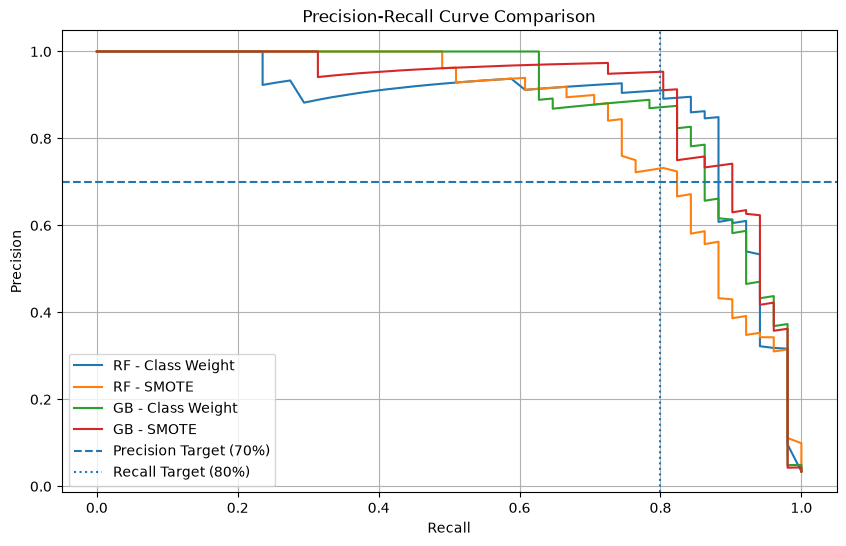

In [27]:
plt.figure(figsize=(10, 6))

for name, model in models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_val,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.axhline(
    y=0.70,
    linestyle='--',
    label='Precision Target (70%)'
)

plt.axvline(
    x=0.80,
    linestyle=':',
    label='Recall Target (80%)'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')

plt.legend()
plt.grid(True)
plt.show()

# Hyperparameter tuning

In [29]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

In [31]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation ready")

5-Fold Stratified Cross-Validation ready


In [32]:
rf_param_grid = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [None, 10, 15, 20, 25],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=rf_param_grid,
    n_iter=30,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best RF parameters:")
print(rf_search.best_params_)

print("\nBest CV F1-score:")
print(rf_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best RF parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 25}

Best CV F1-score:
0.8257370420205759


### Tune Gradient Boosting

In [35]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

# Create pipeline
gb_pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

# Define parameters
gb_param_grid = {
    'classifier__n_estimators': [100, 150, 200, 300],
    'classifier__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'classifier__max_depth': [2, 3, 4],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__subsample': [0.8, 0.9, 1.0]
}

# Create search object
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_grid,
    n_iter=30,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Gradient Boosting search object created")

Gradient Boosting search object created


In [36]:
gb_search.fit(X_train, y_train)

print("Best GB parameters:")
print(gb_search.best_params_)

print("\nBest CV F1-score:")
print(gb_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best GB parameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.1}

Best CV F1-score:
0.7078181564358998


In [37]:
# Extract best models

best_rf_model = rf_search.best_estimator_
best_gb_model = gb_search.best_estimator_

print("Tuned models loaded successfully")

Tuned models loaded successfully


In [38]:
# Random Forest predictions

tuned_rf_pred = best_rf_model.predict(X_val)

tuned_rf_prob = best_rf_model.predict_proba(X_val)[:, 1]

print("TUNED RANDOM FOREST")
print("-------------------")

print("Accuracy:", accuracy_score(y_val, tuned_rf_pred))
print("Precision:", precision_score(y_val, tuned_rf_pred))
print("Recall:", recall_score(y_val, tuned_rf_pred))
print("F1-Score:", f1_score(y_val, tuned_rf_pred))
print("ROC-AUC:", roc_auc_score(y_val, tuned_rf_prob))
print("PR-AUC:", average_precision_score(y_val, tuned_rf_prob))

TUNED RANDOM FOREST
-------------------
Accuracy: 0.9906666666666667
Precision: 0.9111111111111111
Recall: 0.803921568627451
F1-Score: 0.8541666666666666
ROC-AUC: 0.9815491413956887
PR-AUC: 0.8734357550787368


In [39]:
# Gradient Boosting predictions

tuned_gb_pred = best_gb_model.predict(X_val)

tuned_gb_prob = best_gb_model.predict_proba(X_val)[:, 1]

print("TUNED GRADIENT BOOSTING")
print("-----------------------")

print("Accuracy:", accuracy_score(y_val, tuned_gb_pred))
print("Precision:", precision_score(y_val, tuned_gb_pred))
print("Recall:", recall_score(y_val, tuned_gb_pred))
print("F1-Score:", f1_score(y_val, tuned_gb_pred))
print("ROC-AUC:", roc_auc_score(y_val, tuned_gb_prob))
print("PR-AUC:", average_precision_score(y_val, tuned_gb_prob))

TUNED GRADIENT BOOSTING
-----------------------
Accuracy: 0.9793333333333333
Precision: 0.6351351351351351
Recall: 0.9215686274509803
F1-Score: 0.752
ROC-AUC: 0.9873070000947238
PR-AUC: 0.9154377172497236


In [40]:
tuned_models = {
    'Tuned Random Forest': best_rf_model,
    'Tuned Gradient Boosting': best_gb_model
}

tuned_threshold_results = []

for name, model in tuned_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    for i, threshold in enumerate(thresholds):

        p = precision[i]
        r = recall[i]

        f1 = (
            2 * p * r / (p + r)
            if p + r > 0 else 0
        )

        tuned_threshold_results.append({
            'Model': name,
            'Threshold': threshold,
            'Precision': p,
            'Recall': r,
            'F1-Score': f1
        })

tuned_threshold_df = pd.DataFrame(tuned_threshold_results)

eligible_tuned = tuned_threshold_df[
    (tuned_threshold_df['Precision'] >= 0.70) &
    (tuned_threshold_df['Recall'] >= 0.80)
]

if not eligible_tuned.empty:

    best_tuned_thresholds = (
        eligible_tuned
        .sort_values(
            ['Recall', 'F1-Score'],
            ascending=False
        )
        .groupby('Model')
        .head(1)
    )

    display(best_tuned_thresholds.round(4))

else:
    print("No tuned model satisfies both targets.")

,Model,Threshold,Precision,Recall,F1-Score
1551,Tuned Gradient Boosting,0.5324,0.7015,0.9216,0.7966
86,Tuned Random Forest,0.3959,0.8491,0.8824,0.8654


In [41]:
# Extract feature importance

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,Rotational speed [rpm],0.198530
3,Torque [Nm],0.188472
6,Machine Power,0.185094
4,Tool wear [min],0.143410
7,Wear Torque Interaction,0.111326
5,Temperature Difference,0.092424
0,Air temperature [K],0.044483
1,Process temperature [K],0.027255
8,Type_L,0.004570
9,Type_M,0.004436


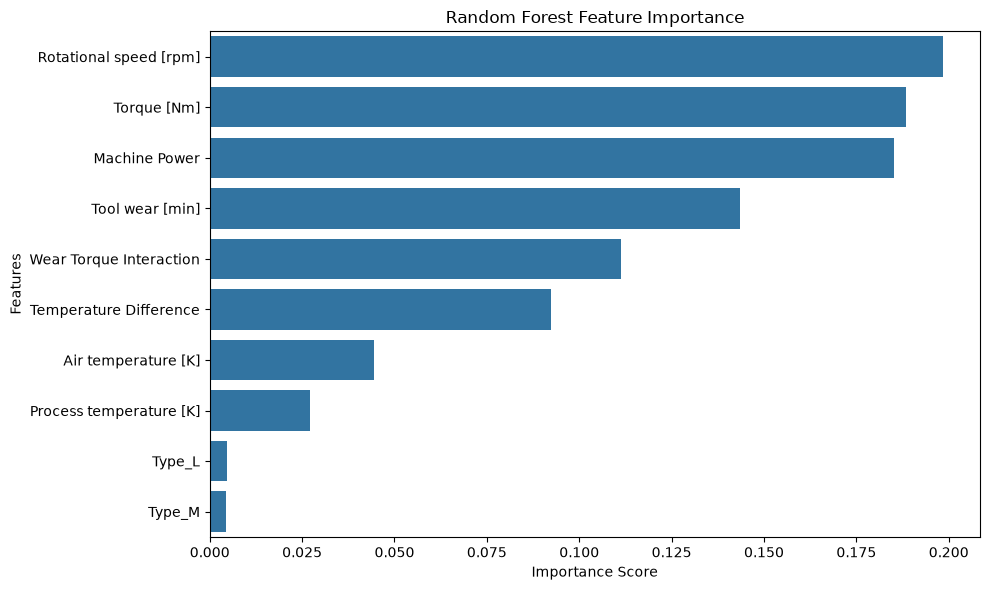

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [43]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 15.7 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


In [44]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [45]:
# Extract the tuned Random Forest classifier

explainer = shap.TreeExplainer(best_rf_model)

# Calculate SHAP values using validation data

shap_values = explainer.shap_values(X_val)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


In [46]:
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    print("Failure class SHAP shape:", shap_values[1].shape)
else:
    print("SHAP array shape:", shap_values.shape)

SHAP output type: <class 'numpy.ndarray'>
SHAP array shape: (1500, 10, 2)


In [47]:
# Extract SHAP values for failure class (Class 1)

shap_values_failure = shap_values[:, :, 1]

print("Failure SHAP shape:", shap_values_failure.shape)

Failure SHAP shape: (1500, 10)


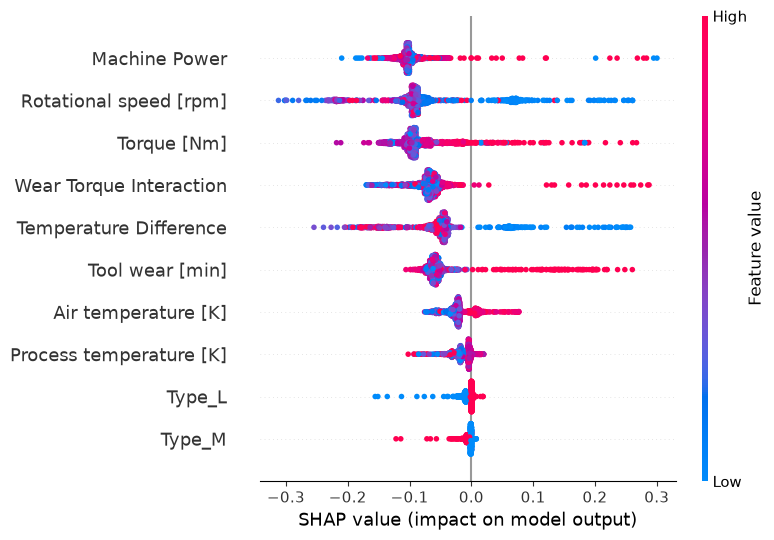

In [48]:
# SHAP Summary Plot

shap.summary_plot(
    shap_values_failure,
    X_val,
    plot_type='dot',
    show=True
)

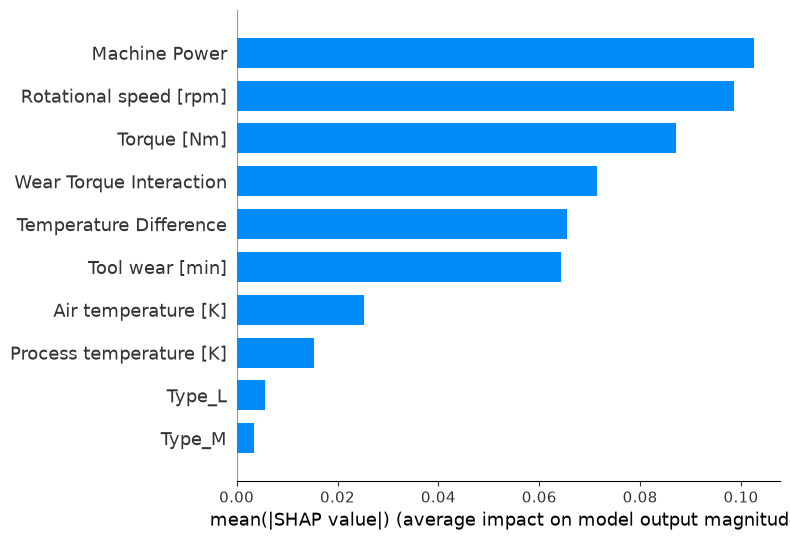

In [49]:
shap.summary_plot(
    shap_values_failure,
    X_val,
    plot_type='bar',
    show=True
)

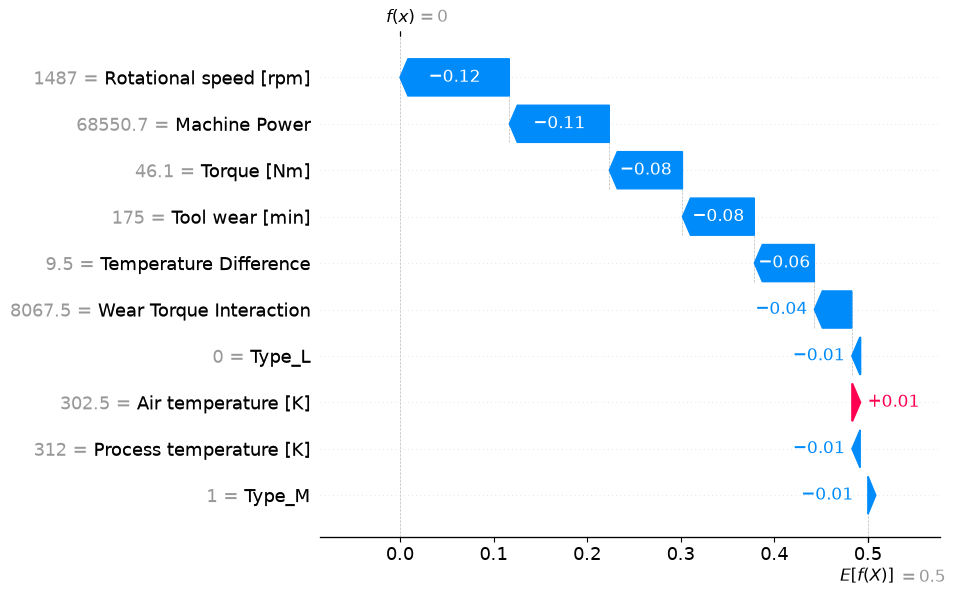

In [50]:
# Select one machine record

sample_index = 0

# Create SHAP explanation for failure class

shap_explanation = shap.Explanation(
    values=shap_values_failure[sample_index],
    base_values=explainer.expected_value[1],
    data=X_val.iloc[sample_index].values,
    feature_names=X_val.columns.tolist()
)

# Generate waterfall plot

shap.plots.waterfall(shap_explanation)

In [51]:
# Final model predictions on untouched test data

final_model = best_rf_model

y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply selected validation threshold
final_threshold = 0.3959

y_test_pred = (
    y_test_prob >= final_threshold
).astype(int)

print("Final model testing completed!")

Final model testing completed!


In [52]:
print("FINAL RANDOM FOREST - TEST RESULTS")
print("----------------------------------")

print("Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("Precision:",
      precision_score(y_test, y_test_pred))

print("Recall:",
      recall_score(y_test, y_test_pred))

print("F1-Score:",
      f1_score(y_test, y_test_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_prob))

print("PR-AUC:",
      average_precision_score(y_test, y_test_prob))

FINAL RANDOM FOREST - TEST RESULTS
----------------------------------
Accuracy: 0.988
Precision: 0.8
Recall: 0.8627450980392157
F1-Score: 0.8301886792452831
ROC-AUC: 0.9864612511671336
PR-AUC: 0.9030217507055256


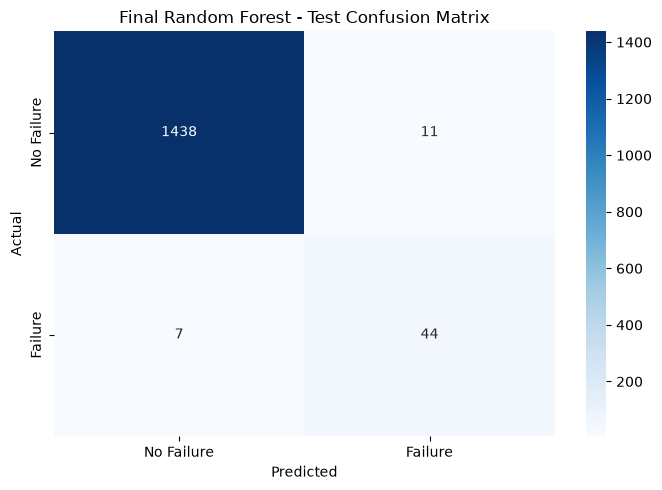

In [53]:
cm_final = confusion_matrix(
    y_test,
    y_test_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.title('Final Random Forest - Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

In [54]:
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['No Failure', 'Failure']
))

              precision    recall  f1-score   support

  No Failure       1.00      0.99      0.99      1449
     Failure       0.80      0.86      0.83        51

    accuracy                           0.99      1500
   macro avg       0.90      0.93      0.91      1500
weighted avg       0.99      0.99      0.99      1500



In [55]:
import os
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

# Save model and prediction configuration together
final_model_bundle = {
    "model": best_rf_model,
    "threshold": 0.3959,
    "features": X_train.columns.tolist(),
    "model_name": "Tuned Random Forest",
    "test_accuracy": 0.988,
    "test_precision": 0.80,
    "test_recall": 0.862745,
    "test_f1": 0.830189,
    "test_roc_auc": 0.986461,
    "test_pr_auc": 0.903022
}

joblib.dump(
    final_model_bundle,
    "models/final_predictive_maintenance_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [57]:
import os
import joblib
from pathlib import Path

# Locate project root
cwd = Path.cwd()

if (cwd / "models").exists():
    project_root = cwd
elif (cwd.parent / "models").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Cannot locate project models folder")

# Prepare model directory
model_dir = project_root / "models"
model_dir.mkdir(exist_ok=True)

# Create model bundle
final_model_bundle = {
    "model": best_rf_model,
    "threshold": 0.3959,
    "features": X_train.columns.tolist(),
    "model_name": "Tuned Random Forest",

    "test_accuracy": 0.988,
    "test_precision": 0.80,
    "test_recall": 0.862745,
    "test_f1": 0.830189,
    "test_roc_auc": 0.986461,
    "test_pr_auc": 0.903022
}

# Save model
model_path = model_dir / "final_predictive_maintenance_model.pkl"

joblib.dump(final_model_bundle, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("File size:", round(model_path.stat().st_size / 1024, 2), "KB")

Model saved successfully!
Location: C:\Users\User\PREDICTIVE_MAINTAINANCE\notebooks\models\final_predictive_maintenance_model.pkl
File size: 5738.09 KB


In [58]:
import os
from pathlib import Path

print("Jupyter working directory:")
print(os.getcwd())

print("\nModel file location:")

model_path = Path("models/final_predictive_maintenance_model.pkl")

print("Exists:", model_path.exists())

if model_path.exists():
    print("Full path:", model_path.resolve())
    print("File size:", model_path.stat().st_size, "bytes")

Jupyter working directory:
C:\Users\User\PREDICTIVE_MAINTAINANCE\notebooks

Model file location:
Exists: True
Full path: C:\Users\User\PREDICTIVE_MAINTAINANCE\notebooks\models\final_predictive_maintenance_model.pkl
File size: 5875803 bytes


In [1]:
import sys
import sklearn
import joblib

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Scikit-learn version:", sklearn.__version__)
print("Joblib version:", joblib.__version__)

Python executable: C:\Users\User\anaconda3\python.exe
Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Scikit-learn version: 1.9.0
Joblib version: 1.5.3
